In [92]:
#import libraries
import pandas as pd
import numpy as np


In [93]:
#DATA LOADING
from google.colab import files

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset loaded successfully")

Saving netflix_titles.csv to netflix_titles (1).csv
Dataset loaded successfully


In [94]:
# Data Understanding

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

Number of Rows: 8812
Number of Columns: 12

Column Names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


In [95]:
# Data Inspection

print("First 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

First 5 Records:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8812 entries, 0 to 8811
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8812 non-null   object
 1   type          8812 non-null   object
 2   title         8812 non-null   object
 3   director      6175 non-null   object
 4   cast          7985 non-null   object
 5   country       7979 non-null   object
 6   date_added    8802 non-null   object
 7   release_year  8812 non-null   int64 
 8   rating        8808 non-null   object
 9   duration      8809 non-null   object
 10  listed_in     8812 non-null   object
 11  description   8812 non-null   object
dtypes: int64(1), object(11)
memory usage: 826.3+ KB


In [96]:
# Missing Value Analysis

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
show_id            0
type               0
title              0
director        2637
cast             827
country          833
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [97]:
# Duplicate Value Analysis

duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

Number of Duplicate Rows: 5


In [98]:
# Data Cleaning - Remove Duplicate Rows

df = df.drop_duplicates()

print("Duplicate rows removed successfully")
print("Number of Duplicate Rows:", df.duplicated().sum())
print("Updated Dataset Shape:", df.shape)

Duplicate rows removed successfully
Number of Duplicate Rows: 0
Updated Dataset Shape: (8807, 12)


In [99]:
# Data Cleaning - Handle Missing Values

df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')
df['date_added'] = df['date_added'].fillna('Unknown')
df['rating'] = df['rating'].fillna('Unknown')
df['duration'] = df['duration'].fillna('Unknown')

print("Missing values handled successfully")

print("\nMissing Values After Cleaning:")
print(df.isnull().sum().sum())

Missing values handled successfully

Missing Values After Cleaning:
0


In [100]:
# Data Preprocessing

df['date_added'] = pd.to_datetime(
    df['date_added'],
    errors='coerce'
)

print("Date format converted successfully")

print("\nData Types:")
print(df.dtypes)

Date format converted successfully

Data Types:
show_id                 object
type                    object
title                   object
director                object
cast                    object
country                 object
date_added      datetime64[ns]
release_year             int64
rating                  object
duration                object
listed_in               object
description             object
dtype: object


Content Type Analysis:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


<Axes: title={'center': 'Movies vs TV Shows'}, xlabel='Content Type', ylabel='Number of Titles'>

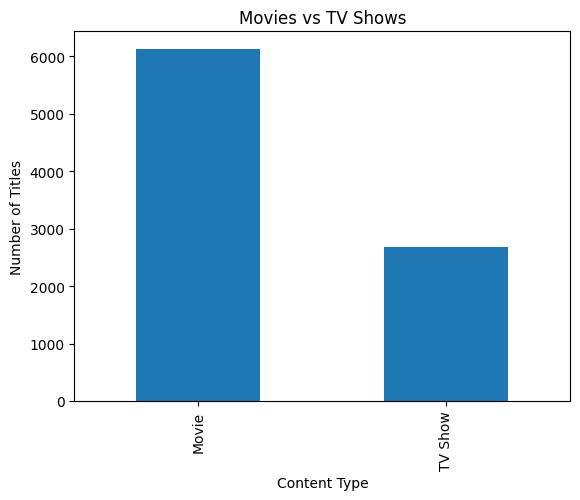

In [101]:
# Data Analysis - Movies vs TV Shows

type_count = df['type'].value_counts()

print("Content Type Analysis:")
print(type_count)
type_count.plot(
    kind='bar',
    title='Movies vs TV Shows',
    xlabel='Content Type',
    ylabel='Number of Titles'
)

Release Year Analysis:
release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64


<Axes: title={'center': 'Content Release Trend by Year'}, xlabel='Release Year', ylabel='Number of Titles'>

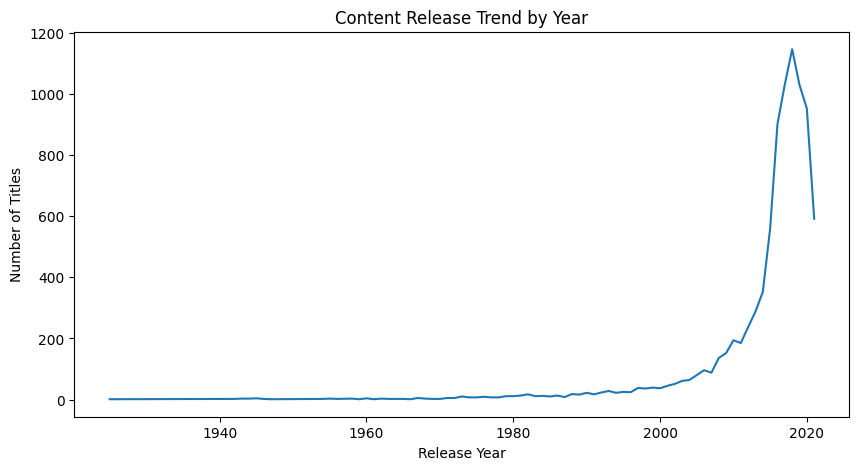

In [102]:
# Data Analysis - Release Year Analysis

release_year_count = df['release_year'].value_counts().sort_index()

print("Release Year Analysis:")
print(release_year_count)
release_year_count.plot(
    kind='line',
    title='Content Release Trend by Year',
    xlabel='Release Year',
    ylabel='Number of Titles',
    figsize=(10, 5)
)

Rating Analysis:
rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
Unknown        4
NC-17          3
UR             3
66 min         1
74 min         1
84 min         1
Name: count, dtype: int64


<Axes: title={'center': 'Content Rating Distribution'}, xlabel='Rating', ylabel='Number of Titles'>

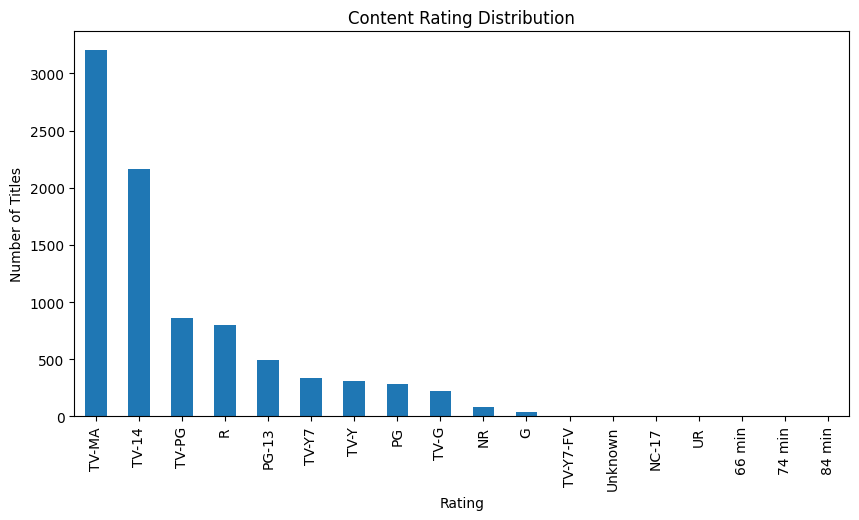

In [103]:
# Data Analysis - Rating Analysis

rating_count = df['rating'].value_counts()

print("Rating Analysis:")
print(rating_count)
rating_count.plot(
    kind='bar',
    title='Content Rating Distribution',
    xlabel='Rating',
    ylabel='Number of Titles',
    figsize=(10, 5)
)

Top 10 Countries:
country
United States     3690
India             1046
Unknown            831
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Name: count, dtype: int64


<Axes: title={'center': 'Top 10 Countries by Number of Titles'}, xlabel='Country', ylabel='Number of Titles'>

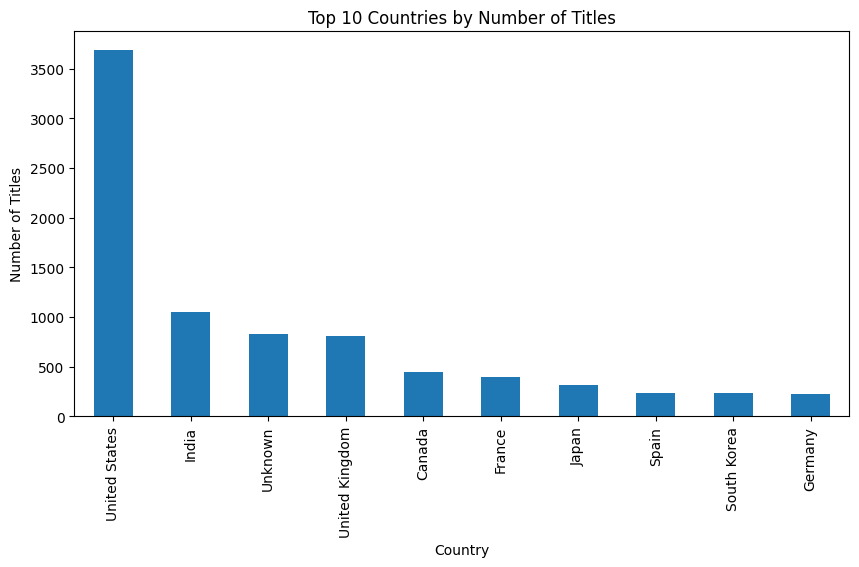

In [104]:
# Data Analysis - Top 10 Countries

country_count = (
    df['country']
    .str.split(',')
    .explode()
    .str.strip()
    .value_counts()
)

print("Top 10 Countries:")
print(country_count.head(10))

country_count.head(10).plot(
    kind='bar',
    title='Top 10 Countries by Number of Titles',
    xlabel='Country',
    ylabel='Number of Titles',
    figsize=(10, 5)
)

Top 10 Genres:
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


<Axes: title={'center': 'Top 10 Genres'}, xlabel='Genre', ylabel='Number of Titles'>

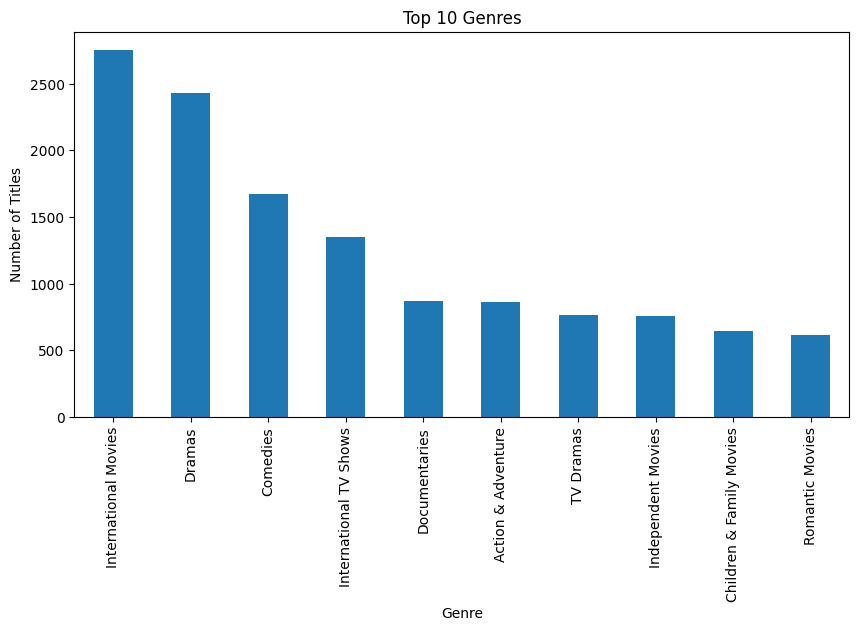

In [105]:
# Data Analysis - Top 10 Genres

genre_count = (
    df['listed_in']
    .str.split(',')
    .explode()
    .str.strip()
    .value_counts()
)

print("Top 10 Genres:")
print(genre_count.head(10))

genre_count.head(10).plot(
    kind='bar',
    title='Top 10 Genres',
    xlabel='Genre',
    ylabel='Number of Titles',
    figsize=(10, 5)
)

In [106]:
# Final Data Check

print("Final Dataset Shape:", df.shape)

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nTotal Duplicate Rows:")
print(df.duplicated().sum())

print("\nFirst 5 Records of Cleaned Dataset:")
display(df.head())

Final Dataset Shape: (8807, 12)

Total Missing Values:
98

Total Duplicate Rows:
0

First 5 Records of Cleaned Dataset:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [107]:
# Save Cleaned Dataset

df.to_csv("cleaned_netflix_titles.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [108]:
# Final Analysis Summary

print("FINAL DATASET SUMMARY")
print("---------------------")

print("Total Titles:", len(df))
print("Total Columns:", len(df.columns))

print("\nContent Type:")
print(df['type'].value_counts())

print("\nTop 5 Ratings:")
print(df['rating'].value_counts().head(5))

print("\nTop 5 Genres:")
print(genre_count.head(5))

print("\nTop 5 Countries:")
print(country_count.head(5))

FINAL DATASET SUMMARY
---------------------
Total Titles: 8807
Total Columns: 12

Content Type:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Top 5 Ratings:
rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
Name: count, dtype: int64

Top 5 Genres:
listed_in
International Movies      2752
Dramas                    2427
Comedies                  1674
International TV Shows    1351
Documentaries              869
Name: count, dtype: int64

Top 5 Countries:
country
United States     3690
India             1046
Unknown            831
United Kingdom     806
Canada             445
Name: count, dtype: int64


In [109]:
# Importing Matplotlib
import matplotlib.pyplot as plt

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


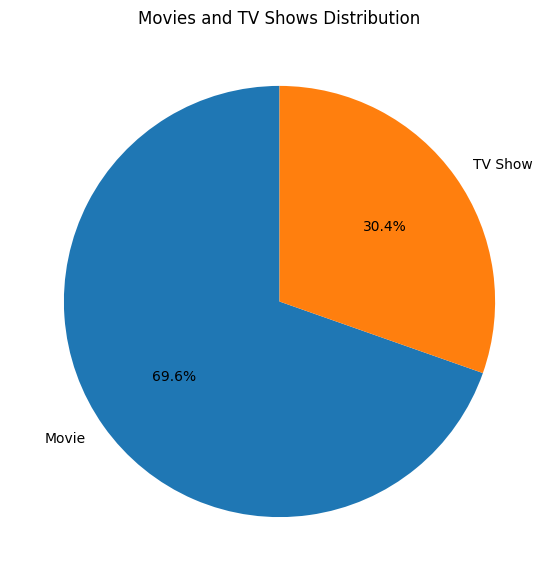

In [110]:
# Counting Movies and TV Shows
type_count = df["type"].value_counts()

# Displaying Movies and TV Shows Distribution
print(type_count)

# Visualizing Movies and TV Shows Distribution
plt.figure(figsize=(7, 7))
plt.pie(
    type_count.values,
    labels=type_count.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Movies and TV Shows Distribution")
plt.show()

country
United States     3689
India             1046
Unknown            831
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Name: count, dtype: int64


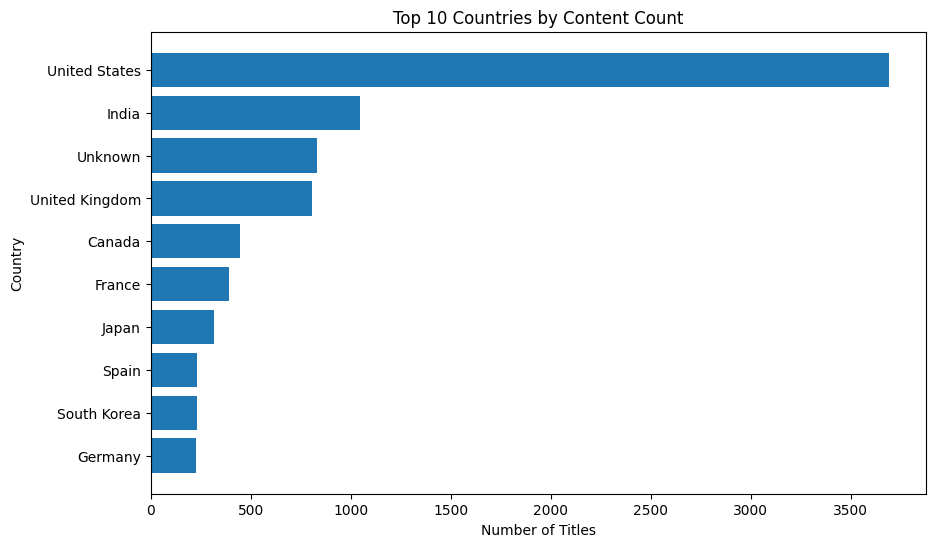

In [111]:
# Counting Titles by Country
country_count = (
    df["country"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
)

# Displaying Top 10 Countries
print(country_count.head(10))

# Visualizing Top 10 Countries
country_visual = country_count.head(10).sort_values()

plt.figure(figsize=(10, 6))
plt.barh(country_visual.index, country_visual.values)
plt.title("Top 10 Countries by Content Count")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.show()

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


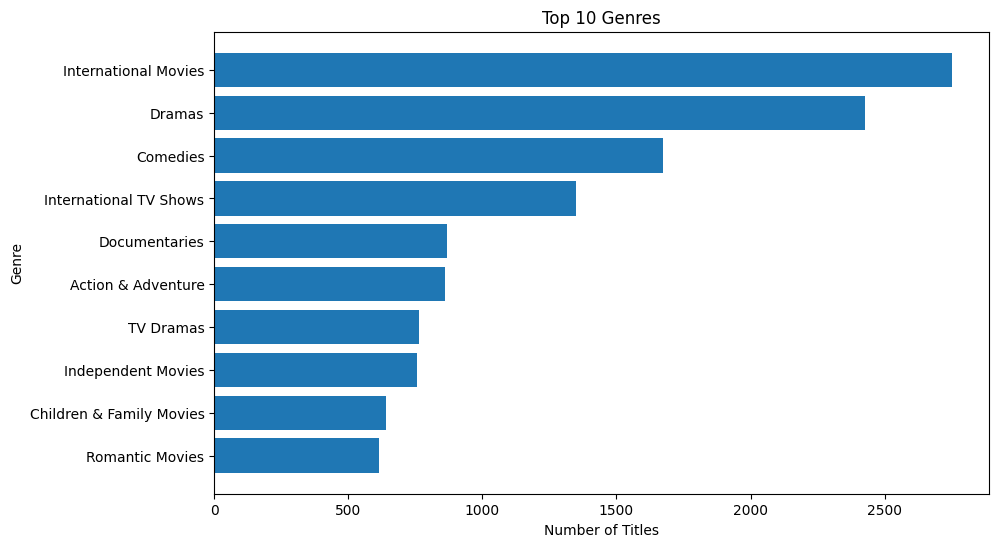

In [112]:
# Counting Genres
genre_count = (
    df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
)

# Displaying Top 10 Genres
print(genre_count.head(10))

# Visualizing Top 10 Genres
genre_visual = genre_count.head(10).sort_values()

plt.figure(figsize=(10, 6))
plt.barh(genre_visual.index, genre_visual.values)
plt.title("Top 10 Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.show()

rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64


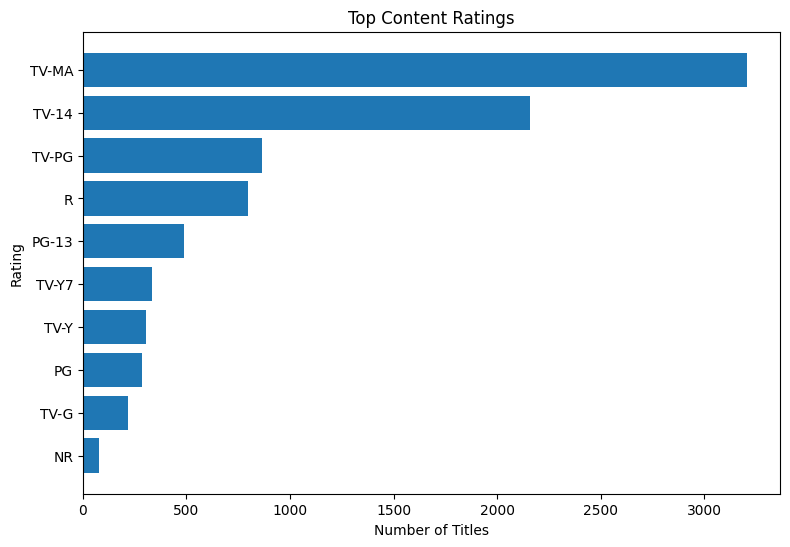

In [113]:
# Counting Content Ratings
rating_count = df["rating"].dropna().value_counts()

# Displaying Content Ratings
print(rating_count.head(10))

# Visualizing Content Ratings
rating_visual = rating_count.head(10).sort_values()

plt.figure(figsize=(9, 6))
plt.barh(rating_visual.index, rating_visual.values)
plt.title("Top Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")
plt.show()

release_year
2012     237
2013     288
2014     352
2015     560
2016     902
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, dtype: int64


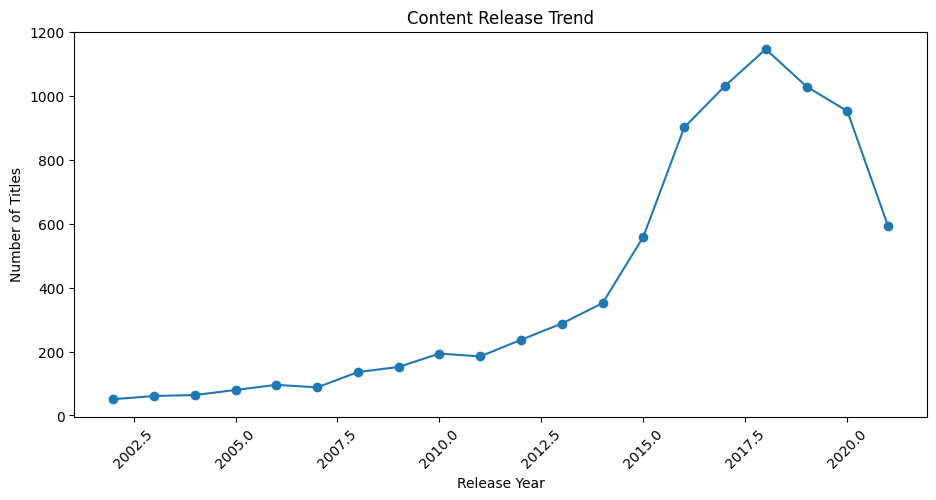

In [114]:
# Counting Titles by Release Year
year_count = df["release_year"].dropna().value_counts().sort_index()

# Displaying Recent Release Year Counts
print(year_count.tail(10))

# Visualizing Content Release Trend
year_visual = year_count.tail(20)

plt.figure(figsize=(11, 5))
plt.plot(year_visual.index, year_visual.values, marker="o")
plt.title("Content Release Trend")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()